In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path


data_dir = Path("data")
if not data_dir.exists():
    data_dir = Path("..") / "data"

c1_train = pd.read_csv(data_dir / "case1" / "train1.csv")
c1_test = pd.read_csv(data_dir / "case1" / "test1.csv")
c2_train = pd.read_csv(data_dir / "case2" / "train2.csv")
c2_test = pd.read_csv(data_dir / "case2" / "test2.csv")

In [15]:
dfs = [c1_train, c1_test, c2_train, c2_test]

for df in dfs:
    # Convert RPM to kRPM
    df["speed_krpm"] = df["speed_rpm"] / 1000

    # Create differential pressure
    df["delta_p"] = df["outlet_pressure_bar"] - df["inlet_pressure_bar"]

    # Drop old columns
    df.drop(
        columns=["speed_rpm", "inlet_pressure_bar", "outlet_pressure_bar"],
        inplace=True
    )

In [16]:
c1_train

,pump_id,elapsed_s,operating_state,power_w,flow_m3_h,speed_krpm,delta_p
0,99223468_model_01,14.5,stable,669.992714,0.652884,4.230396,1.357291
1,99223468_model_01,24.5,stable,931.528480,43.040564,3.796520,0.293043
2,99223468_model_01,34.5,stable,724.198083,40.939560,3.508264,0.185766
3,99223468_model_01,44.5,stable,99.463217,11.857951,1.498405,0.163881
4,99223468_model_01,64.5,stable,608.195308,36.000996,3.224874,0.231682
...,...,...,...,...,...,...,...
475,99223468_model_01,5944.5,stable,815.229829,3.032111,4.376002,1.462426
476,99223468_model_01,5964.5,stable,515.961500,5.566221,3.514587,0.927272
477,99223468_model_01,5974.5,stable,534.173942,22.873572,2.935130,0.499988
478,99223468_model_01,5984.5,stable,154.677482,3.776250,2.214153,0.378757


In [20]:
all_data = pd.concat([c1_train, c1_test, c2_train, c2_test])

all_data[["speed_krpm", "delta_p", "power_w", "flow_m3_h"]].describe()

,speed_krpm,delta_p,power_w,flow_m3_h
count,180450.000000,180450.000000,180450.000000,180450.000000
mean,2.504052,0.436368,314.401809,12.530099
std,0.825111,0.298923,256.677122,8.374278
min,0.987144,-0.196580,21.285478,0.019673
25%,1.811114,0.192545,107.661220,5.994054
50%,2.506114,0.372484,236.944568,11.005568
75%,3.193103,0.633409,456.853764,17.748935
max,4.813199,1.764468,2201.655665,56.823209


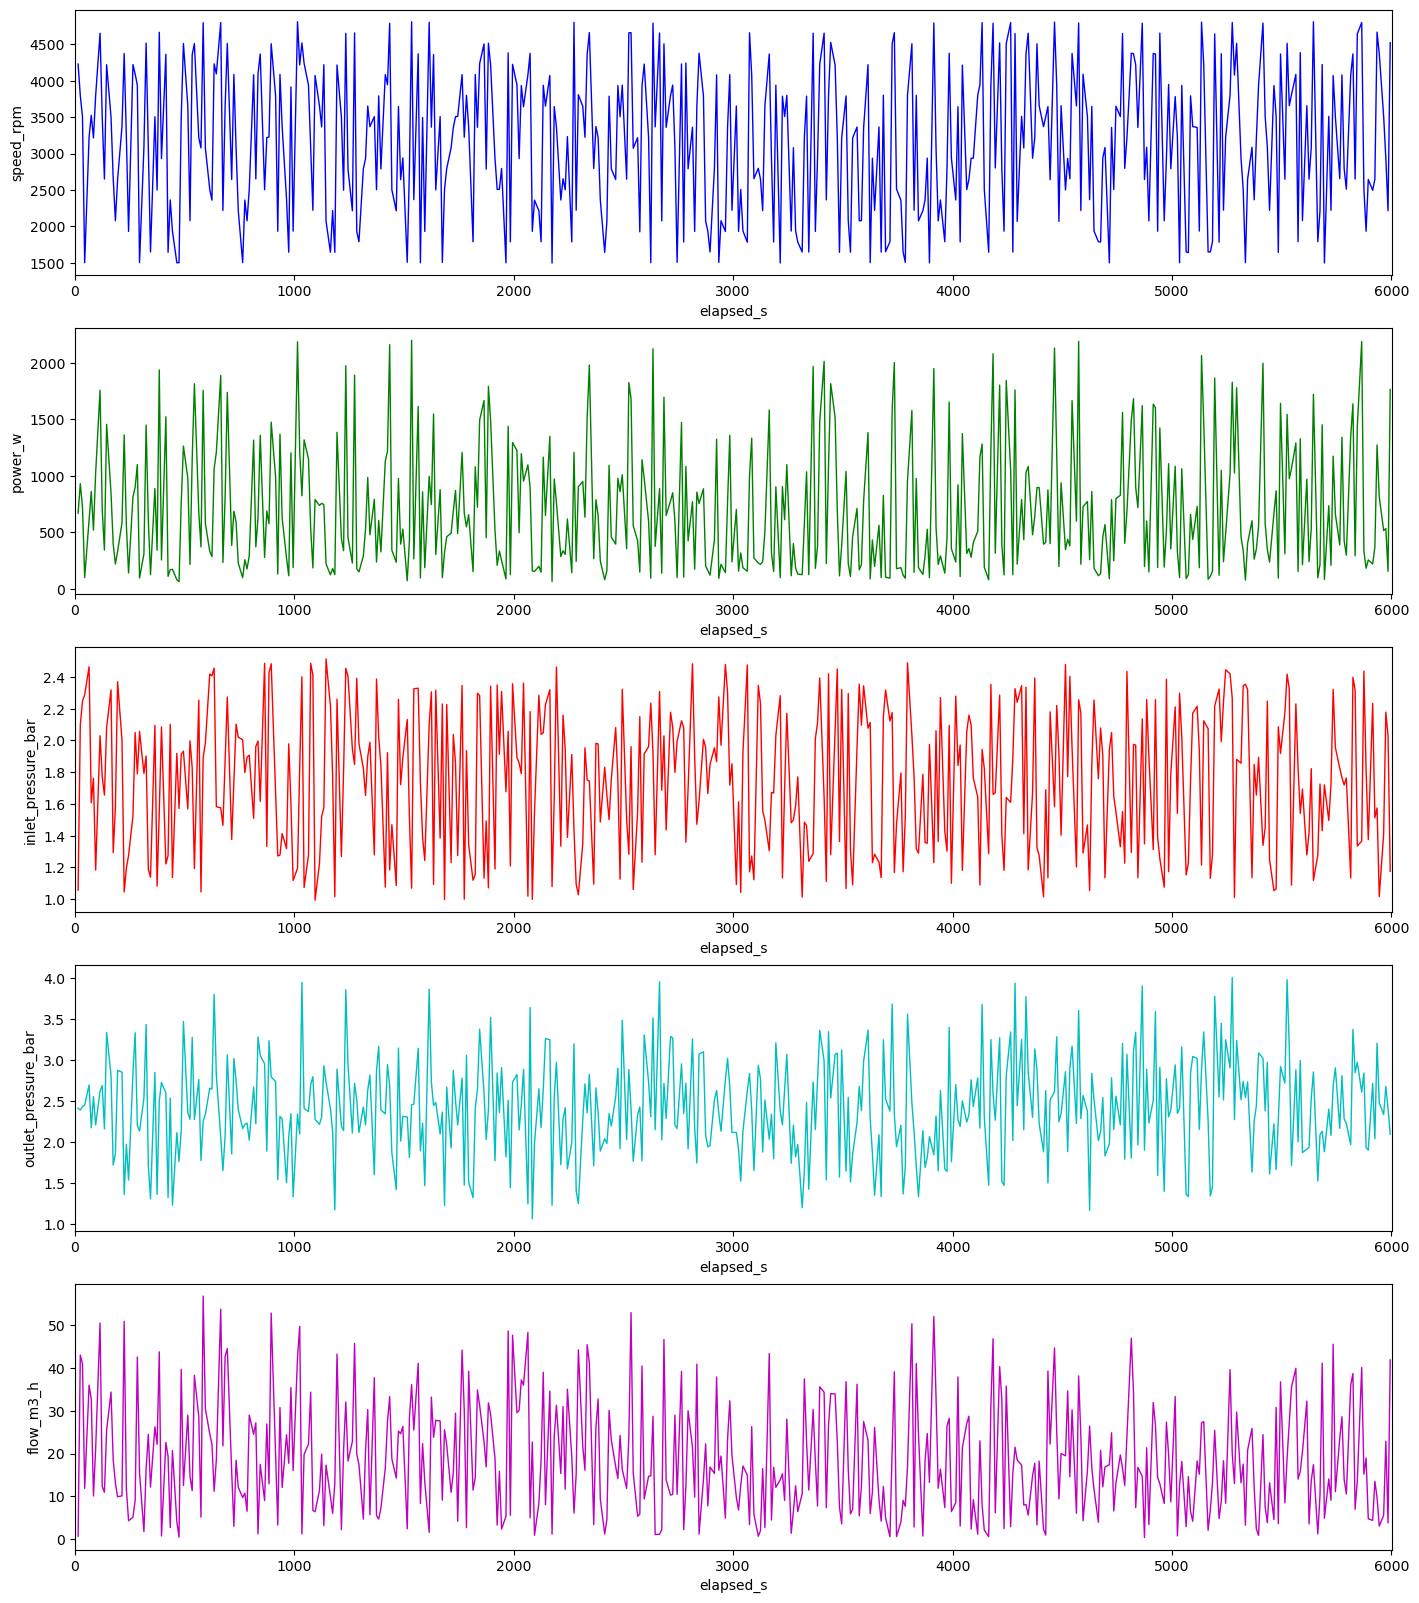

In [9]:
fig, axes = plt.subplots(5, 1, figsize=[17,20])
colors=['b','g','r','c', 'm']

for i, ax in enumerate(axes):
    ax.plot(c1_train["elapsed_s"],c1_train.iloc[:, [i+3]], linewidth=1, color=colors[i])
    ax.set_xlim(left=0, right=(c1_train["elapsed_s"].max()+10))
    ax.set_ylabel(c1_train.columns[i+3])
    ax.set_xlabel('elapsed_s')

plt.show()

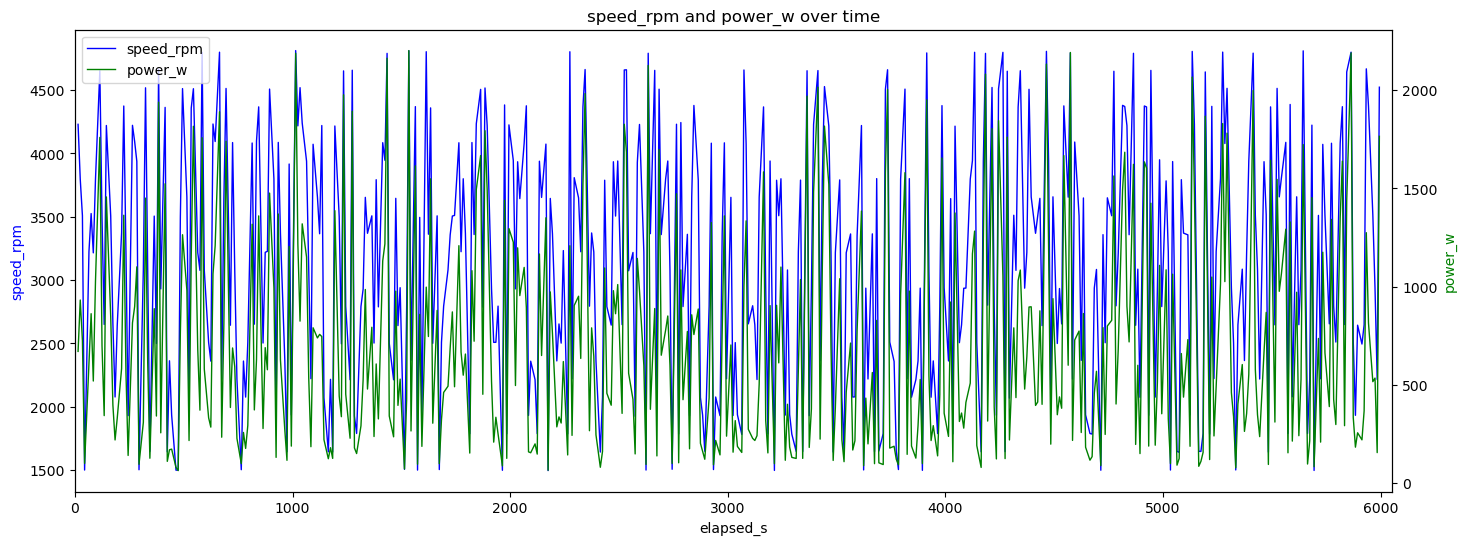

In [12]:
feature_1 = "speed_rpm"
feature_2 = "power_w"
plot_df = c1_train.sort_values("elapsed_s")

fig, ax1 = plt.subplots(figsize=(17, 6))

line_1, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_1], linewidth=1, color="b", label=feature_1)
line_2, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_2], linewidth=1, color="g", label=feature_2)

ax1.set_xlim(left=0, right=plot_df["elapsed_s"].max() + 60)
ax1.set_xlabel("elapsed_s")
ax1.set_ylabel(f"{feature_1} / {feature_2}")
ax1.set_title(f"{feature_1} and {feature_2} over time")
ax1.legend([line_1, line_2], [feature_1, feature_2], loc="upper left")

plt.show()

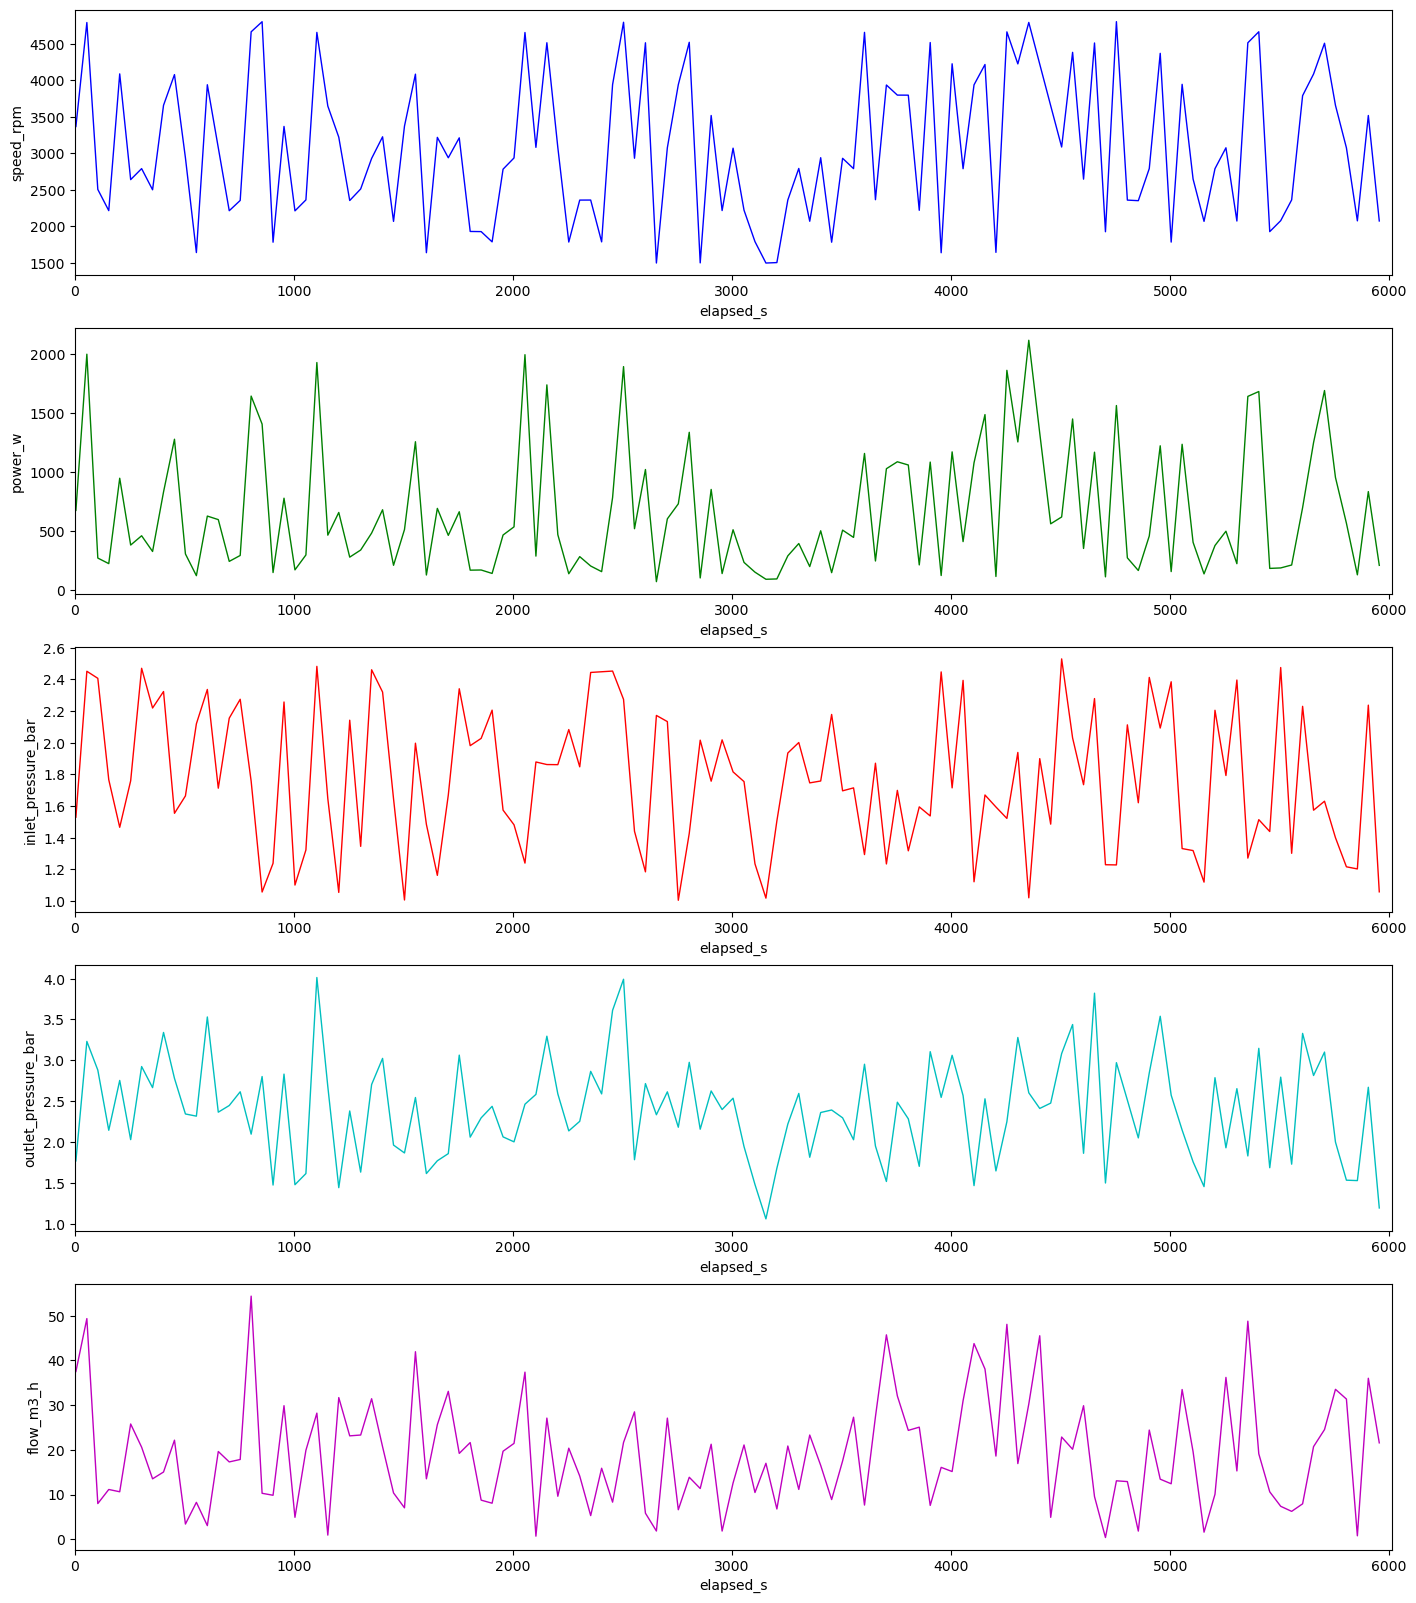

In [ ]:
fig, axes = plt.subplots(5, 1, figsize=[17,20])
colors=['b','g','r','c', 'm']

for i, ax in enumerate(axes):
    ax.plot(c1_test["elapsed_s"],c1_test.iloc[:, [i+3]], linewidth=1, color=colors[i])
    ax.set_xlim(left=0, right=(c1_test["elapsed_s"].max()+60))
    ax.set_ylabel(c1_test.columns[i+3])
    ax.set_xlabel('elapsed_s')

plt.show()

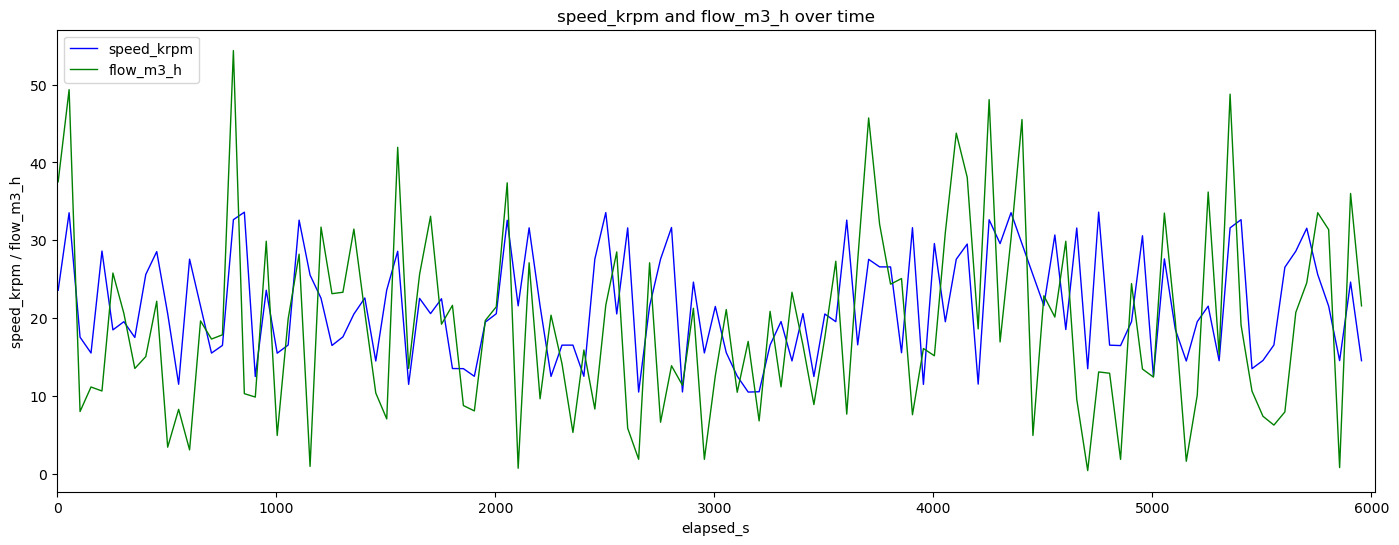

In [ ]:
feature_1 = "speed_krpm"
feature_2 = "flow_m3_h"
plot_df = c1_test.sort_values("elapsed_s")

fig, ax1 = plt.subplots(figsize=(17, 6))

line_1, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_1], linewidth=1, color="b", label=feature_1)
line_2, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_2], linewidth=1, color="g", label=feature_2)

ax1.set_xlim(left=0, right=plot_df["elapsed_s"].max() + 60)
ax1.set_xlabel("elapsed_s")
ax1.set_ylabel(f"{feature_1} / {feature_2}")
ax1.set_title(f"{feature_1} and {feature_2} over time")
ax1.legend([line_1, line_2], [feature_1, feature_2], loc="upper left")

plt.show()

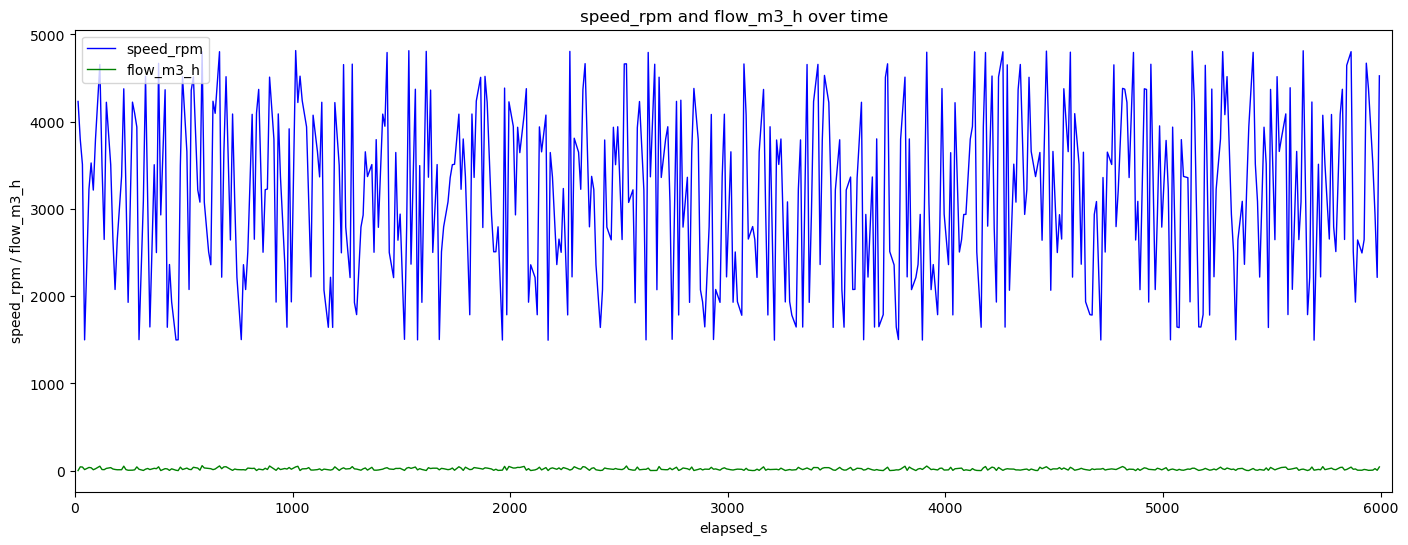

In [14]:
feature_1 = "speed_rpm"
feature_2 = "flow_m3_h"
plot_df = c1_train.sort_values("elapsed_s")

fig, ax1 = plt.subplots(figsize=(17, 6))

line_1, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_1], linewidth=1, color="b", label=feature_1)
line_2, = ax1.plot(plot_df["elapsed_s"], plot_df[feature_2], linewidth=1, color="g", label=feature_2)

ax1.set_xlim(left=0, right=plot_df["elapsed_s"].max() + 60)
ax1.set_xlabel("elapsed_s")
ax1.set_ylabel(f"{feature_1} / {feature_2}")
ax1.set_title(f"{feature_1} and {feature_2} over time")
ax1.legend([line_1, line_2], [feature_1, feature_2], loc="upper left")

plt.show()

/var/folders/yc/hj112b594w727n5n4pblx23m0000gn/T/ipykernel_62606/2172485477.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


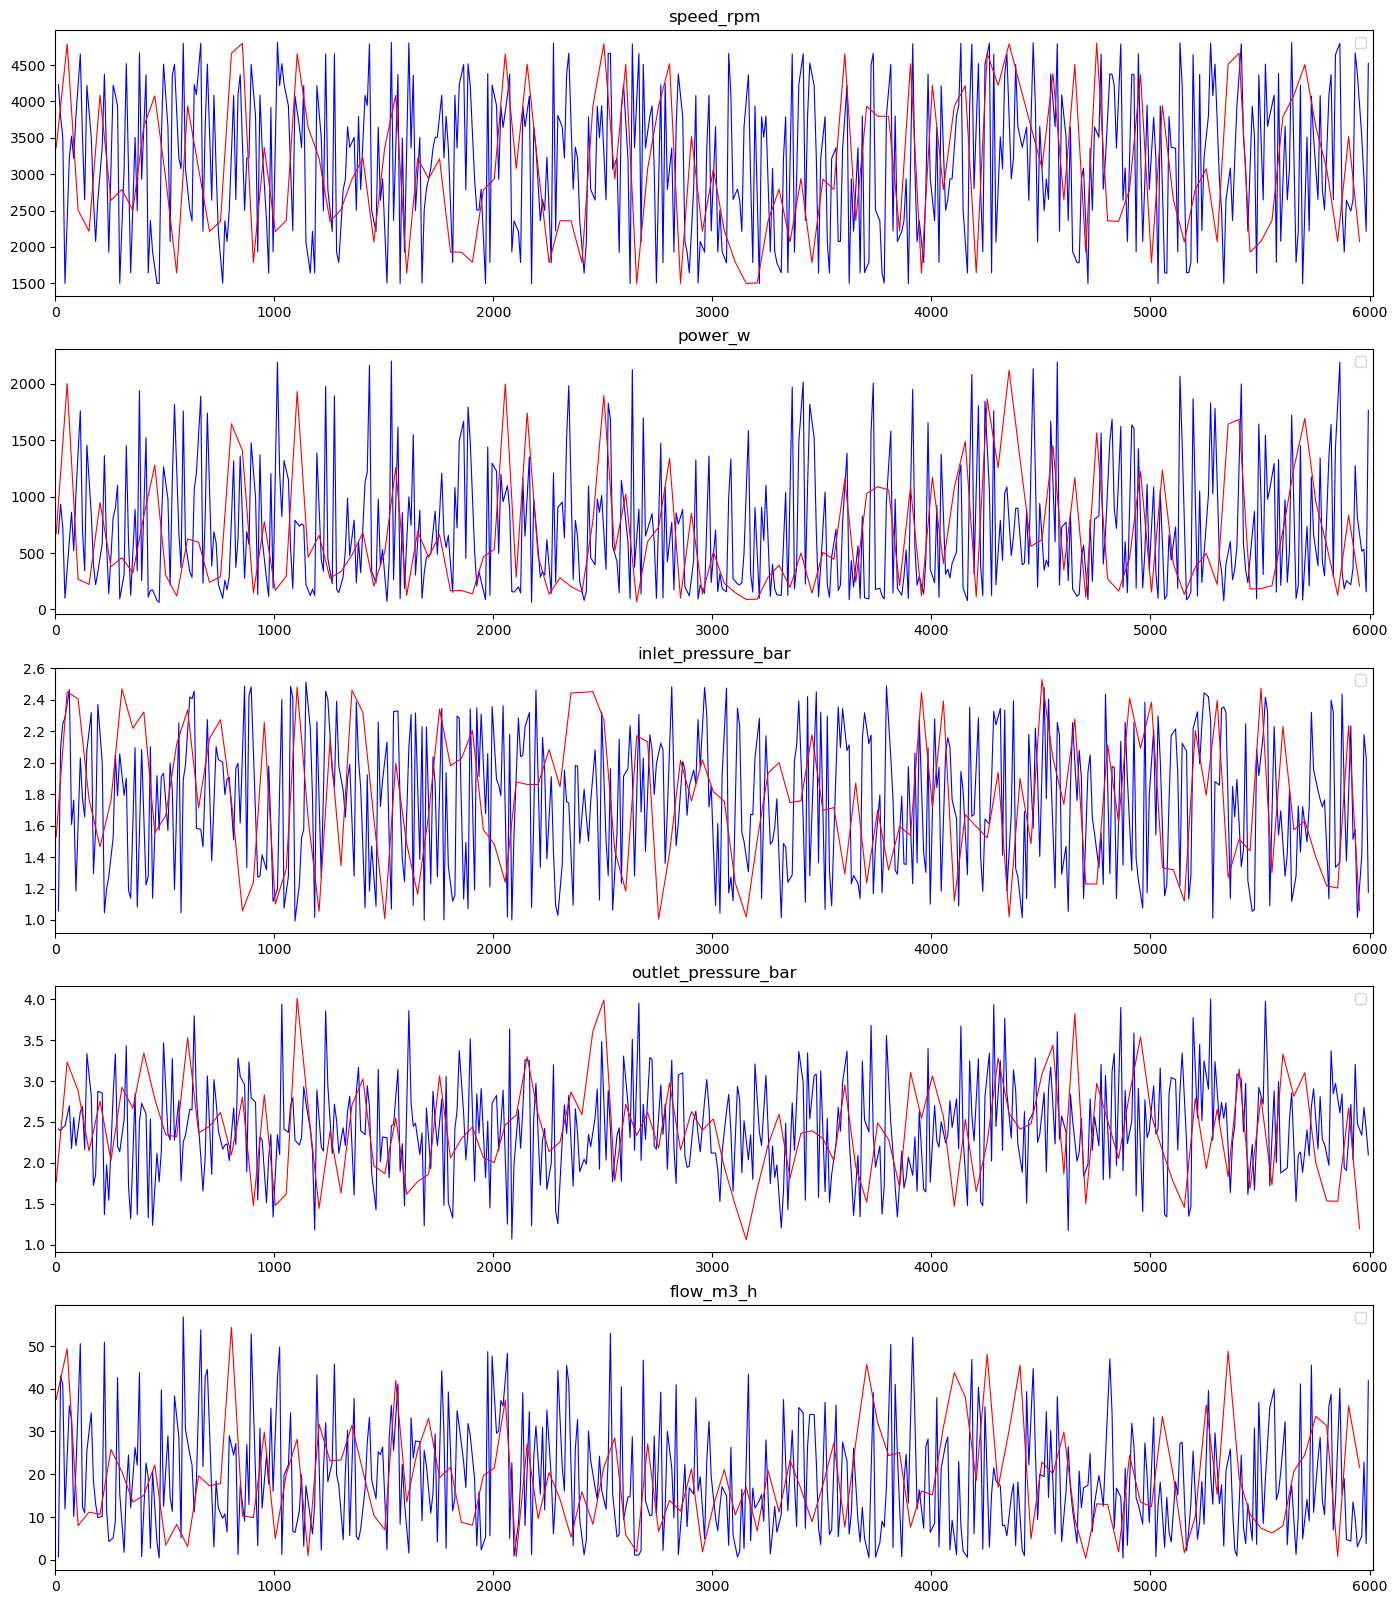

In [40]:
fig, axes = plt.subplots(5, 1, figsize=[17,20])

for i, ax in enumerate(axes):
    ax.plot(c1_train["elapsed_s"],c1_train.iloc[:, [i+3]], linewidth=0.8, color='b')
    ax.plot(c1_test["elapsed_s"],c1_test.iloc[:, [i+3]], linewidth=0.8, color='r')
    ax.set_xlim(left=0, right=(c1_test["elapsed_s"].max()+60))
    ax.set_title(c1_test.columns[i+3])
    ax.legend()

plt.show()

In [45]:
print(np.corrcoef(N, y)[0,1])

0.48032212187994755


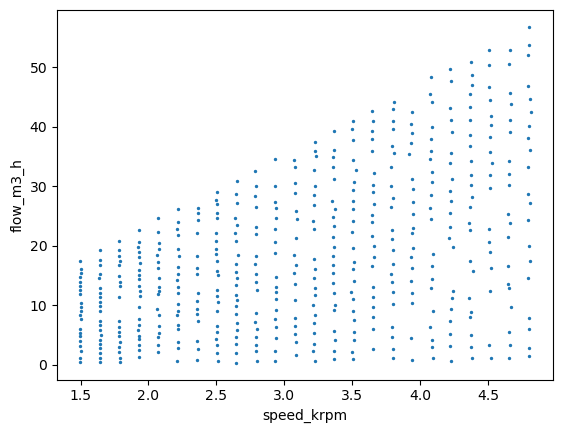

In [46]:
plt.scatter(N, y, s=2)
plt.xlabel("speed_krpm")
plt.ylabel("flow_m3_h")
plt.show()


In [52]:
print(c1_train[["flow_m3_h",
                "speed_krpm",
                "delta_p",
                "power_w"]].corr())

            flow_m3_h  speed_krpm   delta_p   power_w
flow_m3_h    1.000000    0.480322 -0.011799  0.646600
speed_krpm   0.480322    1.000000  0.836032  0.913282
delta_p     -0.011799    0.836032  1.000000  0.717465
power_w      0.646600    0.913282  0.717465  1.000000


In [42]:
N = c1_train["speed_krpm"]
Q = c1_train["flow_m3_h"]

k = (N * Q).sum() / (N**2).sum()

print(k)

Q_pred = k * N

5.96715820123579


In [43]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(Q, Q_pred)
r2 = r2_score(Q, Q_pred)

print("k =", k)
print("MSE =", mse)
print("R² =", r2)

k = 5.96715820123579
MSE = 131.20630744247643
R² = 0.22992658128918997


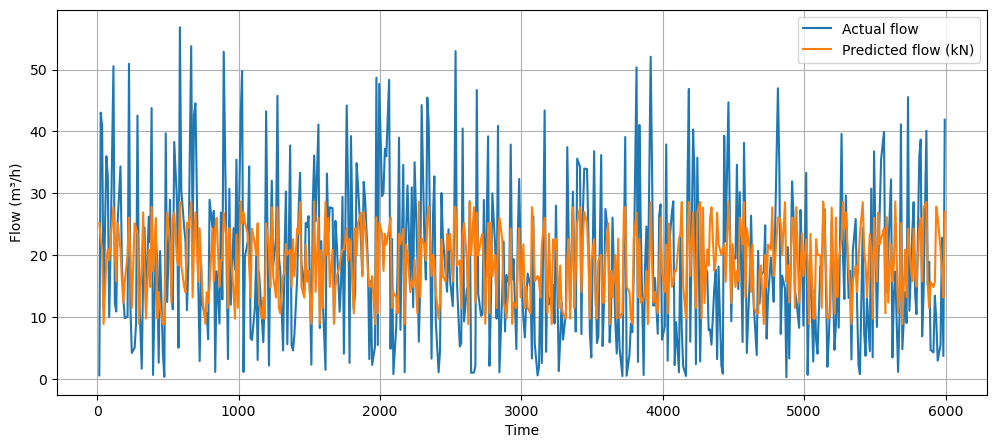

In [44]:
Q_actual = c1_train["flow_m3_h"]
Q_pred = k * c1_train["speed_krpm"]

plt.figure(figsize=(12, 5))

plt.plot(c1_train["elapsed_s"], Q_actual, label="Actual flow")
plt.plot(c1_train["elapsed_s"], Q_pred, label="Predicted flow (kN)")

plt.xlabel("Time")
plt.ylabel("Flow (m³/h)")
plt.legend()
plt.grid(True)
plt.show()

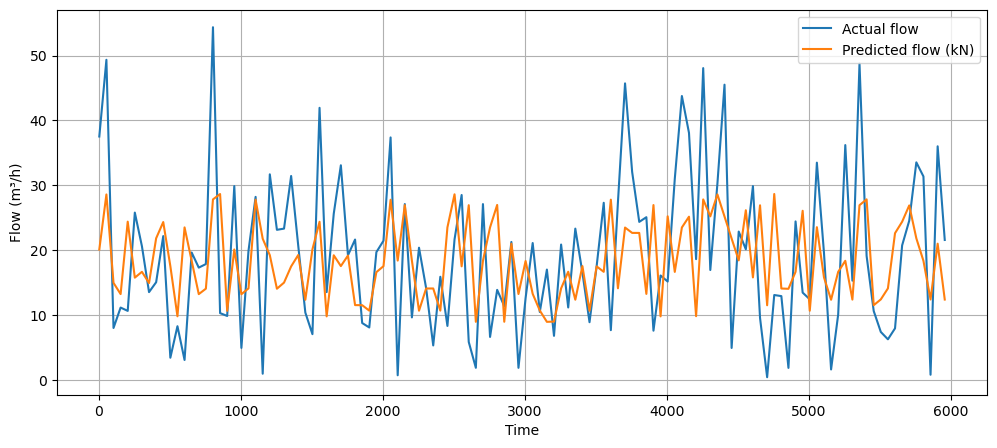

125.00825774773284 0.14229314564820972


In [ ]:
Q_actual = c1_test["flow_m3_h"]
Q_pred = k * c1_test["speed_krpm"]

plt.figure(figsize=(12, 5))

plt.plot(c1_test["elapsed_s"], Q_actual, label="Actual flow")
plt.plot(c1_test["elapsed_s"], Q_pred, label="Predicted flow (kN)")

plt.xlabel("Time")
plt.ylabel("Flow (m³/h)")
plt.legend()
plt.grid(True)
plt.show()

mse = mean_squared_error(Q_actual, Q_pred)
r2 = r2_score(Q_actual, Q_pred)

print(mse, r2)


Q = kN
MSE: 131.2063
R² : 0.2299

Q = k√ΔP
MSE: 210.1280
R² : -0.2333

Q = k∛P
MSE: 108.6167
R² : 0.3625

Linear Regression
MSE: 11.9199
R² : 0.9300


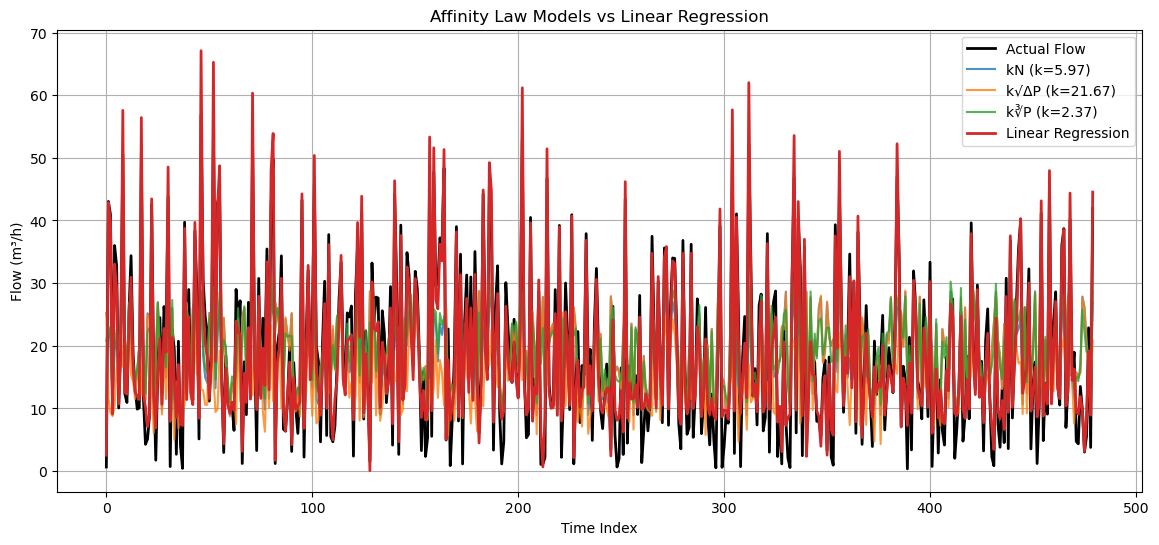

In [41]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Target
y = c1_train["flow_m3_h"]

# Features derived from affinity laws
N = c1_train["speed_krpm"]
DP = np.sqrt(c1_train["delta_p"])
P = np.cbrt(c1_train["power_w"])

# Best k for y = kx
def fit_k(x, y):
    return (x * y).sum() / (x**2).sum()

# Fit constants
k_N = fit_k(N, y)
k_DP = fit_k(DP, y)
k_P = fit_k(P, y)

# Predictions
pred_N = k_N * N
pred_DP = k_DP * DP
pred_P = k_P * P

# Standard linear regression
X = c1_train[["speed_krpm", "delta_p", "power_w"]]

lr = LinearRegression()
lr.fit(X, y)

pred_lr = lr.predict(X)

# Metrics
models = {
    "Q = kN": pred_N,
    "Q = k√ΔP": pred_DP,
    "Q = k∛P": pred_P,
    "Linear Regression": pred_lr
}

for name, pred in models.items():
    mse = mean_squared_error(y, pred)
    r2 = r2_score(y, pred)

    print(f"\n{name}")
    print(f"MSE: {mse:.4f}")
    print(f"R² : {r2:.4f}")

# Plot
plt.figure(figsize=(14, 6))

plt.plot(y.values, label="Actual Flow", color="black", linewidth=2)

plt.plot(pred_N.values,
         label=f"kN (k={k_N:.2f})",
         alpha=0.8)

plt.plot(pred_DP.values,
         label=f"k√ΔP (k={k_DP:.2f})",
         alpha=0.8)

plt.plot(pred_P.values,
         label=f"k∛P (k={k_P:.2f})",
         alpha=0.8)

plt.plot(pred_lr,
         label="Linear Regression",
         linewidth=2)

plt.xlabel("Time Index")
plt.ylabel("Flow (m³/h)")
plt.title("Affinity Law Models vs Linear Regression")
plt.legend()
plt.grid(True)

plt.show()